# Behavior Classification: Tree and Ensemble Model Experiment

## 1. Experiment objective and protocol

Predict `others`, `running` and `falling` from 141 transformed sequence features. Read [README](README.md) for input placement, preprocessing and environment setup; recorded result summaries are in [MODELS](../docs/MODELS.md).

**Protocol:** validate the fixed inputs, tune seven tree/ensemble candidates with the same budget, check five seeds, select on validation, compute validation permutation importance, then refit train + validation and evaluate test for reporting.

This notebook orchestrates the experiment. Reusable implementation lives in `src/behavior_modeling/`. It does not preprocess, rebalance or reconstruct inputs. The observations below describe saved experiment `20260825_tree_ensemble_refactor_v01`; they were updated from its recorded outputs without rerunning code.


## 2. Imports and experiment configuration

**Purpose:** Load the small public API used by the notebook and declare the settings that define this experiment.

**Inputs:** Current working directory, installed modeling libraries, and the user-defined experiment identifier.

**Outputs:** Resolved project paths and a concise reproducibility summary.

**Guardrails:** Change `EXPERIMENT_ID` before another complete run. Existing experiment folders are never overwritten.


In [1]:
# Configure one reproducible end-to-end experiment.
# Standard-library imports handle paths, timestamps, and local-module discovery.
from datetime import datetime, timezone
from pathlib import Path
import sys

# Notebook-facing libraries are limited to arrays, compact tables, and figures.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Locate behavioral-detection whether Jupyter starts in this module, the repo root,
# or a nested working directory; this avoids a machine-specific absolute path.
search_roots = (Path.cwd(), *Path.cwd().parents)
PROJECT_DIR = next(
    (
        candidate.resolve()
        for root in search_roots
        for candidate in (root, root / "behavioral-detection")
        if (candidate / "data").is_dir()
    ),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Run this notebook from the repository root or behavioral-detection folder."
    )
# Make the module root importable without installing a separate Python package.
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Import only the public workflow helpers; implementation details stay in src/.
from src.behavior_modeling.artifacts import (
    create_experiment_paths,
    format_saved_artifacts,
    relevant_library_versions,
    save_dataframe,
    save_figure,
    save_model_bundle,
)
from src.behavior_modeling.data import (
    build_feature_names,
    find_exact_row_overlap,
    load_behavior_datasets,
    source_metadata_available,
    summarize_class_distribution,
    summarize_dataset_integrity,
    validate_behavior_datasets,
)
from src.behavior_modeling.evaluation import (
    build_model_comparison,
    compute_permutation_importance,
    evaluate_final_test_set,
    select_final_model,
)
from src.behavior_modeling.modeling import (
    build_model,
    effective_iteration_count,
    evaluate_seed_stability,
    fit_model,
    get_model_availability,
    refit_final_model,
    tune_models,
)

# These values define the experiment contract and must be recorded with the model.
# Increment the versioned ID before a new end-to-end run to prevent overwrite.
EXPERIMENT_ID = "20260825_tree_ensemble_refactor_v01"
RANDOM_SEED, N_TRIALS, EARLY_STOPPING_ROUNDS = 42, 50, 50
STABILITY_SEEDS, NEAR_TIE_THRESHOLD = [17, 42, 83, 123, 2026], 0.005
CLASS_MAPPING = {0: "others", 1: "running", 2: "falling"}
PROBABILITY_ORDER = ["running", "falling", "others"]
DATA_DIR, ARTIFACT_ROOT = PROJECT_DIR / "data", PROJECT_DIR / "artifacts"

# Seed notebook-level NumPy operations and standardize all displayed figures.
np.random.seed(RANDOM_SEED)
sns.set_theme(style="whitegrid", context="notebook")
# Print only the settings a reviewer needs before starting expensive training.
print(
    f"Experiment: {EXPERIMENT_ID}\nTrials/model: {N_TRIALS}\nStability seeds: {STABILITY_SEEDS}\nPrimary metric: macro F1"
)

Experiment: 20260825_tree_ensemble_refactor_v01
Trials/model: 50
Stability seeds: [17, 42, 83, 123, 2026]
Primary metric: macro F1


### Observation

- **Result:** The setup declares 50 trials per available model, five stability seeds and validation macro F1 as the primary metric.
- **Interpretation:** Experiment settings are visible in the setup cell.
- **Decision:** Use a new `EXPERIMENT_ID` for another complete run; preserve settings for a like-for-like comparison.


## 3. Load transformed datasets

**Purpose:** Load the authoritative feature matrices produced by preprocessing without modifying their values.

**Inputs:** `train_cleaned.npz`, `val_cleaned.npz`, and `test_cleaned.npz` under `data/`.

**Outputs:** Train, validation, and test feature/target arrays plus the ordered feature contract.

**Guardrails:** Loading test supports data-contract checks only. No estimator sees test features in this section.


In [2]:
# Load the fixed splits and expose concise aliases for later cells.
# Rebuild the documented column order before accepting any feature matrix.
feature_names = build_feature_names()
# Loading returns arrays unchanged; validation fails fast instead of repairing data.
datasets = load_behavior_datasets(DATA_DIR)
validate_behavior_datasets(datasets, feature_names, list(CLASS_MAPPING))

# These aliases reference the loaded arrays directly; no scaling, sampling, or copy
# is introduced between the preprocessing output and the candidate models.
X_train, y_train = datasets["train"][:2]
X_validation, y_validation = datasets["validation"][:2]
X_test, y_test = datasets["test"][:2]

# Show only split dimensions so the load result stays quick to verify.
loaded_shapes = pd.DataFrame(
    [
        {"split": name, "X shape": values[0].shape, "y shape": values[1].shape}
        for name, values in datasets.items()
    ]
)
display(loaded_shapes)

,split,X shape,y shape
0,train,"(3600, 141)","(3600,)"
1,validation,"(786, 141)","(786,)"
2,test,"(763, 141)","(763,)"


### Observation

- **Result:** Saved outputs contain 3,600 training rows, 786 validation rows and 763 test rows, with 141 features each.
- **Interpretation:** These are the cleaned inputs for the recorded modeling experiment.
- **Decision:** Continue with the input-contract and distribution checks before fitting.


## 4. Dataset integrity and class distribution

**Purpose:** Confirm that all arrays are finite and visualize whether class prevalence differs across splits.

**Inputs:** Loaded datasets and the fixed class mapping.

**Outputs:** A five-column integrity table and one grouped class-count figure.

**Guardrails:** The diagnostic reports stored prevalence exactly as provided; it does not rebalance or repair data.


,split,samples,features,missing_values,infinite_values
0,train,3600,141,0,0
1,validation,786,141,0,0
2,test,763,141,0,0


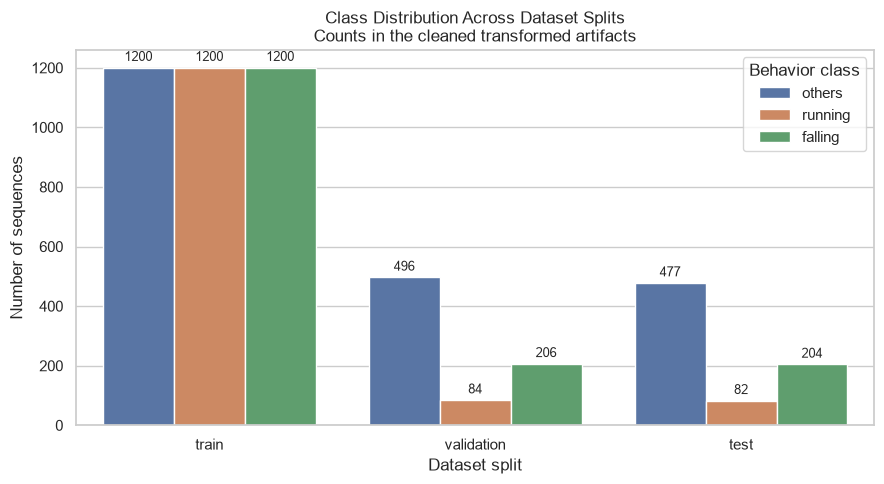

In [3]:
# Summarize the data contract and visualize class counts without altering samples.
# The compact table checks finite values and dimensions; the long-form distribution
# frame is used only to draw class prevalence by split.
integrity_summary = summarize_dataset_integrity(datasets)
class_distribution = summarize_class_distribution(datasets, CLASS_MAPPING)
display(integrity_summary)

# A grouped bar chart makes imbalance visible without displaying a wide pivot table.
dataset_distribution_figure, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=class_distribution, x="split", y="count", hue="class_name", ax=ax)
ax.set_title(
    "Class Distribution Across Dataset Splits\nCounts in the cleaned transformed artifacts"
)
ax.set(xlabel="Dataset split", ylabel="Number of sequences")
ax.legend(title="Behavior class")
# Label exact counts so the saved figure remains useful outside the notebook.
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=9)
dataset_distribution_figure.tight_layout()
plt.show()

_Figure: Stored class counts in the cleaned splits._

### Observation

- **Result:** All feature matrices are finite. Training has 1,200 rows per class; validation/test retain their stored class counts.
- **Interpretation:** Per-class metrics and macro F1 complement aggregate accuracy.
- **Decision:** Preserve the provided distributions during modeling.


## 5. Split diagnostic

**Purpose:** Display exact transformed-row comparisons for the supplied inputs.

**Inputs:** The three loaded feature matrices.

**Outputs:** An annotated comparison matrix.

**Guardrails:** This diagnostic does not modify the inputs or reconstruct splits.


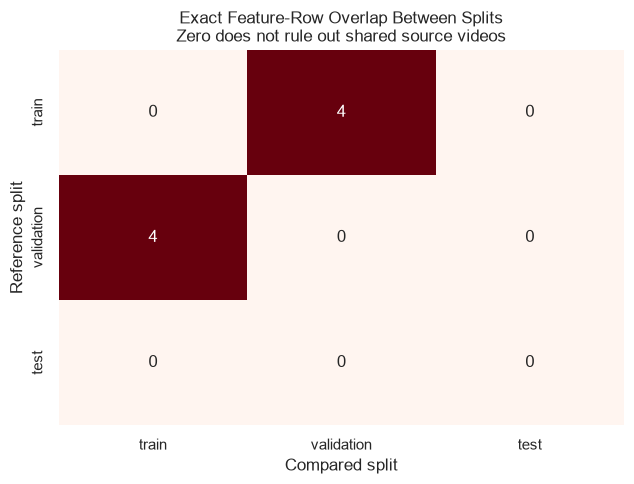

Source/group metadata available: False


In [4]:
# Hash exact rows as a limited cross-split leakage warning signal.
# Hashing compares transformed rows byte-for-byte without rounding or mutation.
exact_overlap = find_exact_row_overlap(datasets)
# Check separately whether source/group IDs exist, because exact-row equality cannot
# detect different windows derived from the same original video.
has_source_metadata = source_metadata_available(datasets)

# The symmetric heatmap keeps all three pairwise comparisons readable at a glance.
leakage_figure, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(exact_overlap, annot=True, fmt="d", cmap="Reds", cbar=False, ax=ax)
ax.set_title(
    "Exact Feature-Row Overlap Between Splits\nZero does not rule out shared source videos"
)
ax.set(xlabel="Compared split", ylabel="Reference split")
leakage_figure.tight_layout()
plt.show()
# Report the provenance limitation next to the overlap result to prevent overclaiming.
print("Source/group metadata available:", has_source_metadata)

_Figure: Off-diagonal cells compare transformed rows across the supplied splits._

### Observation

- **Result:** The saved diagnostic is shown above.
- **Interpretation:** This is an input inspection step, not a model-selection score.
- **Decision:** Keep the fixed inputs unchanged for the recorded experiment.


## 6. Candidate models and tuning setup

**Purpose:** Confirm which of the seven declared candidate families can run in the current environment.

**Inputs:** Installed scikit-learn, XGBoost, and LightGBM packages.

**Outputs:** A compact availability table.

**Guardrails:** Missing XGBoost or LightGBM skips only that candidate. Every available model receives the same trial budget.


In [5]:
# Report candidate availability before starting the expensive tuning stage.
# Core scikit-learn models are always expected; optional import failures affect only
# XGBoost or LightGBM and do not stop the remaining experiment.
model_availability = get_model_availability()
# Keep dependency output decision-focused; detailed import errors remain available
# in the returned frame but are not shown when every candidate is installed.
display(model_availability[["model_name", "available"]])
print(
    f"Available candidates: {int(model_availability['available'].sum())} / {len(model_availability)}"
)

,model_name,available
0,Decision Tree,True
1,Random Forest,True
2,Extra Trees,True
3,Gradient Boosting,True
4,HistGradientBoosting,True
5,XGBoost,True
6,LightGBM,True


Available candidates: 7 / 7


### Observation

- **Result:** In the configured `smart-factory-train` environment, all seven candidate families are currently available.
- **Interpretation:** The experiment can make a complete like-for-like comparison.
- **Decision:** Tune every available model using 50 sequential Optuna trials and validation macro F1 only.


## 7. Hyperparameter tuning

**Purpose:** Find the strongest configuration for each available candidate within the unchanged search spaces.

**Inputs:** Training and validation arrays, 50-trial budget, fixed sampler seed, and early-stopping patience.

**Outputs:** Resolved best parameters and a concise model-level tuning comparison.

**Guardrails:** Optuna fits on training data and optimizes validation macro F1. Test data is absent from the tuning API, and no trial database or trial-history artifacts are written.


Tuning Decision Tree:   0%|          | 0/50 [00:00<?, ?trial/s]

Tuning Random Forest:   0%|          | 0/50 [00:00<?, ?trial/s]

Tuning Extra Trees:   0%|          | 0/50 [00:00<?, ?trial/s]

Tuning Gradient Boosting:   0%|          | 0/50 [00:00<?, ?trial/s]

Tuning HistGradientBoosting:   0%|          | 0/50 [00:00<?, ?trial/s]

Tuning XGBoost:   0%|          | 0/50 [00:00<?, ?trial/s]

Tuning LightGBM:   0%|          | 0/50 [00:00<?, ?trial/s]

,model_name,best_single_validation_macro_f1,best_trial_training_time_seconds,model_status
0,Gradient Boosting,0.9265,5.0508,COMPLETE
1,Extra Trees,0.9226,0.1824,COMPLETE
2,Random Forest,0.9174,0.6958,COMPLETE
3,HistGradientBoosting,0.9131,1.2619,COMPLETE
4,LightGBM,0.9101,0.7565,COMPLETE
5,XGBoost,0.9082,0.8667,COMPLETE
6,Decision Tree,0.8542,0.1599,COMPLETE


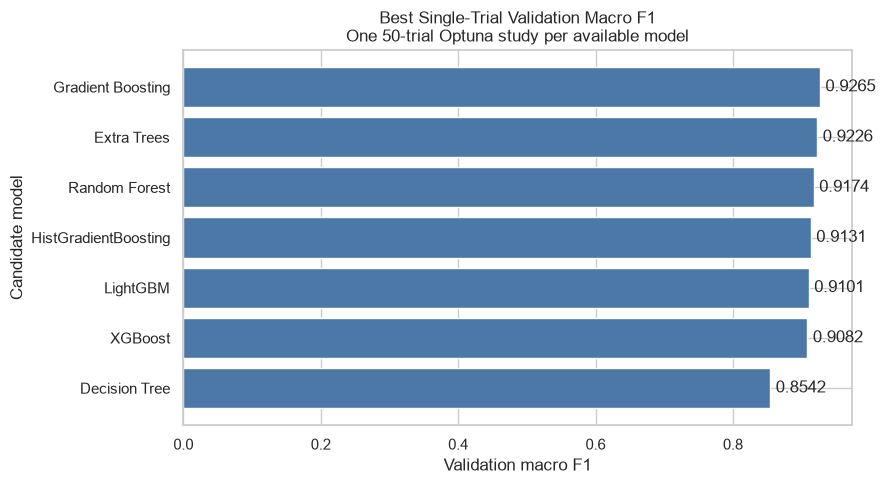

In [6]:
# Tune all available candidates through one shared, validation-only protocol.
# Every available family receives the same trial budget and sampler seed; the helper
# has no test-array parameter, which enforces test isolation at the API boundary.
# The progress bar names the active model and tracks its best completed trial.
tuning_summary, best_params_by_model = tune_models(
    X_train,
    y_train,
    X_validation,
    y_validation,
    CLASS_MAPPING,
    n_trials=N_TRIALS,
    random_seed=RANDOM_SEED,
    early_stopping_rounds=EARLY_STOPPING_ROUNDS,
)
# Failed or unavailable candidates remain in the full summary for reporting, while
# only successful studies can contribute metrics and parameters downstream.
completed_tuning = tuning_summary.query("model_status == 'COMPLETE'").copy()
# Display only score, runtime, and status; complete parameters stay in memory.
tuning_display = completed_tuning[
    [
        "model_name",
        "best_single_validation_macro_f1",
        "best_trial_training_time_seconds",
        "model_status",
    ]
]
display(tuning_display.round(4))

# This chart describes the best isolated trial per family; it is intentionally not
# the final selection chart because seed stability has not been measured yet.
tuning_figure, ax = plt.subplots(figsize=(9, 5))
plot_data = completed_tuning.sort_values("best_single_validation_macro_f1")
ax.barh(
    plot_data["model_name"],
    plot_data["best_single_validation_macro_f1"],
    color="#4C78A8",
)
ax.set_title(
    "Best Single-Trial Validation Macro F1\nOne 50-trial Optuna study per available model"
)
ax.set(xlabel="Validation macro F1", ylabel="Candidate model")
ax.bar_label(ax.containers[0], fmt="%.4f", padding=4)
tuning_figure.tight_layout()
plt.show()

_Figure: Best single validation macro F1 found within each declared search space._

### Observation

- **Result:** Saved results place Gradient Boosting first by isolated trial (`0.9265`), followed by Extra Trees (`0.9226`).
- **Interpretation:** Model choice also considers stability across seeds.
- **Decision:** Carry each resolved configuration into the five-seed comparison.


## 8. Multi-seed stability

**Purpose:** Measure estimator randomness and train–validation behavior for each best configuration.

**Inputs:** Best resolved parameters, fixed train/validation splits, and five declared seeds.

**Outputs:** Individual seed results, an aggregated stability summary, and one error-bar visualization.

**Guardrails:** This is a randomness check on one fixed split, not cross-validation. Test data remains unused.


,model_name,mean_validation_macro_f1,validation_macro_f1_std,mean_generalization_gap
0,Extra Trees,0.9208,0.0036,0.0792
1,Gradient Boosting,0.9200,0.0055,0.0800
2,Random Forest,0.9117,0.0042,0.0883
3,HistGradientBoosting,0.9110,0.0042,0.0867
4,LightGBM,0.9080,0.0039,0.0920
5,XGBoost,0.9039,0.0040,0.0961
6,Decision Tree,0.8530,0.0035,0.1316


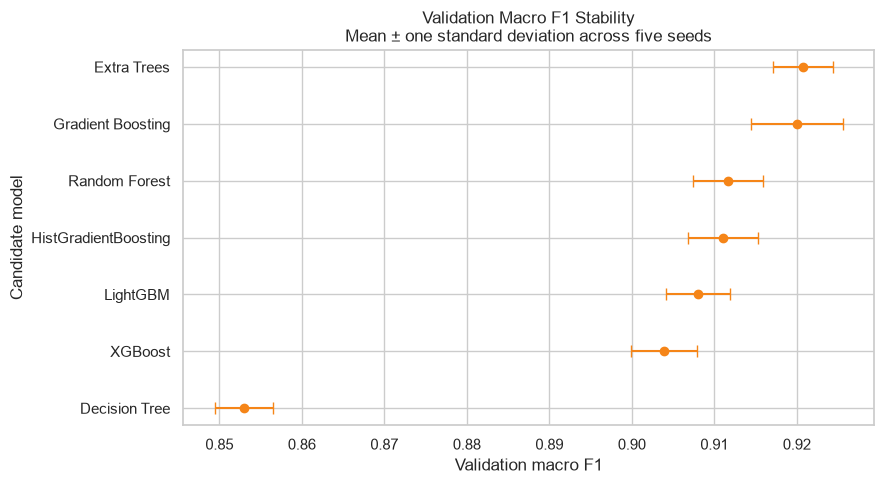

In [7]:
# Retrain each best configuration across the same five random seeds.
# The detailed frame supports representative-seed selection; the aggregated frame
# summarizes mean performance, variation, and train-validation behavior.
seed_results, stability_summary = evaluate_seed_stability(
    best_params_by_model,
    X_train,
    y_train,
    X_validation,
    y_validation,
    CLASS_MAPPING,
    STABILITY_SEEDS,
    EARLY_STOPPING_ROUNDS,
)
# Restrict the notebook table to the three diagnostics used for model selection.
stability_display = stability_summary[
    [
        "model_name",
        "mean_validation_macro_f1",
        "validation_macro_f1_std",
        "mean_generalization_gap",
    ]
]
display(stability_display.round(4))

# Error bars expose estimator randomness that a single best Optuna trial can hide.
validation_seed_stability_figure, ax = plt.subplots(figsize=(9, 5))
plot_data = stability_summary.sort_values("mean_validation_macro_f1")
# Numeric y positions allow model labels and horizontal uncertainty bars to align.
positions = np.arange(len(plot_data))
ax.errorbar(
    plot_data["mean_validation_macro_f1"],
    positions,
    xerr=plot_data["validation_macro_f1_std"],
    fmt="o",
    capsize=4,
    color="#F58518",
)
ax.set_yticks(positions, plot_data["model_name"])
ax.set_title(
    "Validation Macro F1 Stability\nMean ± one standard deviation across five seeds"
)
ax.set(xlabel="Validation macro F1", ylabel="Candidate model")
validation_seed_stability_figure.tight_layout()
plt.show()

_Figure: Mean validation macro F1 and one standard deviation across seeds._

### Observation

- **Result:** Extra Trees records `0.9208 ± 0.0036`; Gradient Boosting records `0.9200 ± 0.0055`.
- **Interpretation:** Extra Trees combines the highest saved mean with lower seed variation among these near-tie candidates.
- **Decision:** Apply the declared near-tie selection rule to the stability summary.


## 9. Final model selection

**Purpose:** Apply the declared near-tie rule and choose a representative seed before any test prediction.

**Inputs:** Tuning summary, stability summary, resolved parameters, and individual seed runs.

**Outputs:** Ranked comparison, near-tie candidates, selected model, parameters, seed, and optional boosting iteration count.

**Guardrails:** Models within `0.005` of the best mean validation macro F1 are tied, then ordered by seed variation, absolute generalization gap, complexity, inference time, and finally mean score.


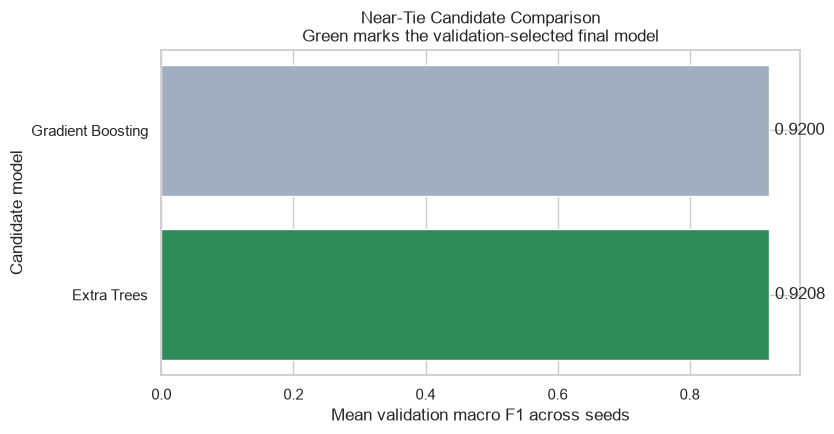

Selected model: Extra Trees
Representative seed: 17
Fixed iterations: None


,selected value
bootstrap,False
criterion,gini
max_depth,23
max_features,log2
min_samples_leaf,2
min_samples_split,2
n_estimators,300


In [8]:
# Combine model evidence and select a stable representative configuration.
# Tuning and multi-seed summaries are merged before applying the fixed near-tie rule.
model_comparison = build_model_comparison(
    tuning_summary, stability_summary, best_params_by_model
)
# Selection uses validation evidence only. The helper first forms the 0.005 near-tie
# set, applies the documented tie-breakers, then chooses the seed nearest the mean.
selection = select_final_model(
    model_comparison, best_params_by_model, seed_results, NEAR_TIE_THRESHOLD
)
# Unpack the locked configuration once so later cells cannot accidentally mix
# parameters, seeds, or iteration counts from different candidates.
selected_model_name = selection["model_name"]
selected_hyperparameters = selection["hyperparameters"]
selected_seed = selection["seed"]
selected_iteration_count = selection["iteration_count"]
near_ties = selection["near_tie_candidates"]

# Plot only practically tied candidates and highlight the rule-selected model.
validation_model_comparison_figure, ax = plt.subplots(figsize=(8.5, 4.5))
colors = [
    "#2E8B57" if name == selected_model_name else "#A0AEC0"
    for name in near_ties["model_name"]
]
ax.barh(near_ties["model_name"], near_ties["mean_validation_macro_f1"], color=colors)
ax.set_title(
    "Near-Tie Candidate Comparison\nGreen marks the validation-selected final model"
)
ax.set(xlabel="Mean validation macro F1 across seeds", ylabel="Candidate model")
ax.bar_label(ax.containers[0], fmt="%.4f", padding=4)
validation_model_comparison_figure.tight_layout()
plt.show()

print(
    f"Selected model: {selected_model_name}\nRepresentative seed: {selected_seed}\nFixed iterations: {selected_iteration_count}"
)
# Present parameters vertically so long dictionaries do not create a wide table.
display(pd.Series(selected_hyperparameters, name="selected value").to_frame())

_Figure: Candidates inside the practical 0.005 validation-macro-F1 tie range._

### Observation

- **Result:** The saved experiment selects Extra Trees with representative seed `17`.
- **Interpretation:** The decision uses the declared stability and near-tie rule.
- **Decision:** Lock the configuration before feature interpretation and final refit.


## 10. Validation feature importance

**Purpose:** Explain the selected development model using validation permutation importance before any test prediction.

**Inputs:** Selected model configuration, training split, validation split, and ordered feature names.

**Outputs:** Complete feature-importance data and a top-15 visualization.

**Guardrails:** Importance does not affect model ranking and does not establish causality. The test set is not used.


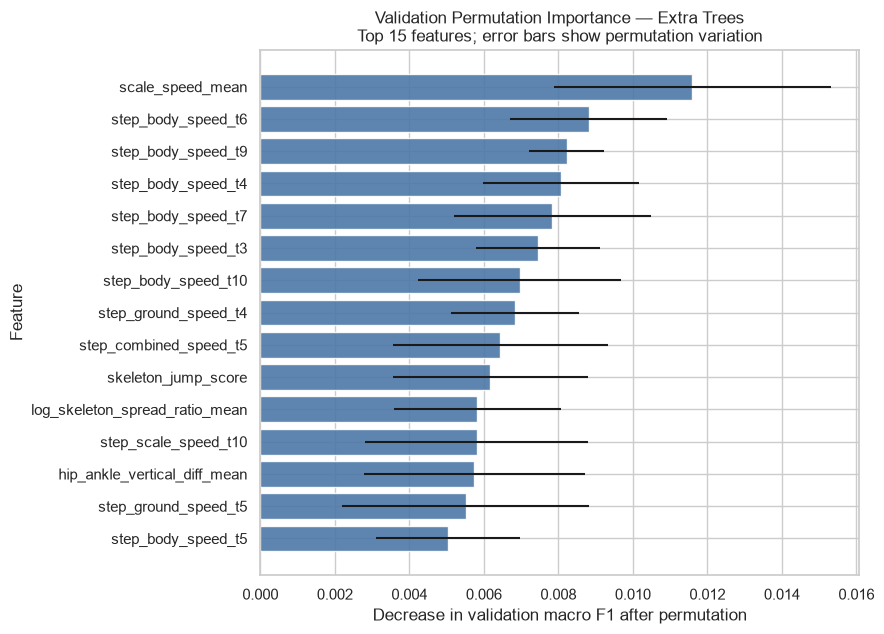

,feature_name,permutation_importance_mean,permutation_importance_std
0,scale_speed_mean,0.01159,0.00372
1,step_body_speed_t6,0.00881,0.00211
2,step_body_speed_t9,0.00822,0.00102
3,step_body_speed_t4,0.00806,0.00209
4,step_body_speed_t7,0.00783,0.00264
5,step_body_speed_t3,0.00745,0.00165
6,step_body_speed_t10,0.00696,0.00272
7,step_ground_speed_t4,0.00684,0.00173
8,step_combined_speed_t5,0.00644,0.00289
9,skeleton_jump_score,0.00617,0.00262


In [9]:
# Fit the selected development model and interpret it on validation data only.
# Recreate the chosen estimator from its locked parameters rather than reusing an
# Optuna trial object with hidden state.
development_model = build_model(
    selected_model_name,
    selected_hyperparameters,
    selected_seed,
    early_stopping_rounds=EARLY_STOPPING_ROUNDS,
)
# Train on the original training split; validation is supplied only where the model
# supports early stopping. Test data is deliberately absent.
fit_model(
    selected_model_name,
    development_model,
    X_train,
    y_train,
    validation_features=X_validation,
    validation_targets=y_validation,
    early_stopping_rounds=EARLY_STOPPING_ROUNDS,
)
# Capture a validation-derived boosting length for the later train-plus-validation
# refit. Non-boosting estimators correctly return None.
development_iterations = effective_iteration_count(
    selected_model_name, development_model
)
if selected_iteration_count is None and development_iterations is not None:
    selected_iteration_count = development_iterations

# Permute validation columns after selection; this explains the locked model and
# cannot feed back into candidate ranking or feature removal.
feature_importance = compute_permutation_importance(
    development_model, X_validation, y_validation, feature_names, RANDOM_SEED
)
# Plot only the top 15 for readability; the complete 141-row frame is saved later.
top_features = feature_importance.head(15).sort_values("permutation_importance_mean")
selected_model_feature_importance_figure, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(
    top_features["feature_name"],
    top_features["permutation_importance_mean"],
    xerr=top_features["permutation_importance_std"],
    color="#4C78A8",
    alpha=0.9,
)
ax.set_title(
    f"Validation Permutation Importance — {selected_model_name}\nTop 15 features; error bars show permutation variation"
)
ax.set(xlabel="Decrease in validation macro F1 after permutation", ylabel="Feature")
selected_model_feature_importance_figure.tight_layout()
plt.show()
display(feature_importance.head(15).round(5))

_Figure: Decrease in validation macro F1 after permuting each feature._

### Observation

- **Result:** The saved importance ranking is led by `scale_speed_mean` and sampled body-speed features, including `step_body_speed_t6` and `step_body_speed_t9`.
- **Interpretation:** These are predictive associations, not causal evidence.
- **Decision:** Keep all 141 inputs for final refit; importance does not change selection.


## 11. Final refit

**Purpose:** Train the locked selected estimator on all available development data.

**Inputs:** Train plus validation arrays, selected parameters, representative seed, and validation-derived iteration count where applicable.

**Outputs:** Final fitted classifier and training-time summary.

**Guardrails:** The test split is not used for fitting or early stopping. Boosting models use an iteration count fixed before this section.


In [10]:
# Refit the locked configuration on train plus validation without test data.
# The helper concatenates the two development splits internally and disables
# held-out early stopping by using the iteration count fixed in the prior section.
final_model, final_training_time, final_training_samples = refit_final_model(
    selected_model_name,
    selected_hyperparameters,
    selected_seed,
    X_train,
    y_train,
    X_validation,
    y_validation,
    fixed_iterations=selected_iteration_count,
    early_stopping_rounds=EARLY_STOPPING_ROUNDS,
)
# Report enough information to verify the final fit without dumping estimator state.
print(
    f"Final model: {selected_model_name}\n"
    f"Training samples: {final_training_samples}\n"
    f"Fixed iterations: {selected_iteration_count}\n"
    f"Training time: {final_training_time:.3f} seconds"
)

Final model: Extra Trees
Training samples: 4386
Fixed iterations: None
Training time: 0.223 seconds


### Observation

- **Result:** Saved output reports Extra Trees refitted on 4,386 train-plus-validation rows.
- **Interpretation:** The selected configuration is now fitted on the development membership.
- **Decision:** Proceed to test reporting without reopening model selection.


## 12. Final test evaluation

**Purpose:** Measure the locked final model once on the untouched test set.

**Inputs:** Final fitted model and test arrays.

**Outputs:** Aggregate metrics, compact per-class metrics, prediction probabilities when supported, and an annotated confusion matrix.

**Guardrails:** Test results are final reporting evidence only. They must not trigger model reselection, retuning, threshold adjustment, or feature changes.


Accuracy: 0.9502 | Macro F1: 0.9341 | Weighted F1: 0.9501 | Inference: 0.0486 s


,class_name,precision,recall,f1,support
0,others,0.9527,0.9706,0.9616,477
1,running,0.9012,0.8902,0.8957,82
2,falling,0.9643,0.9265,0.9450,204


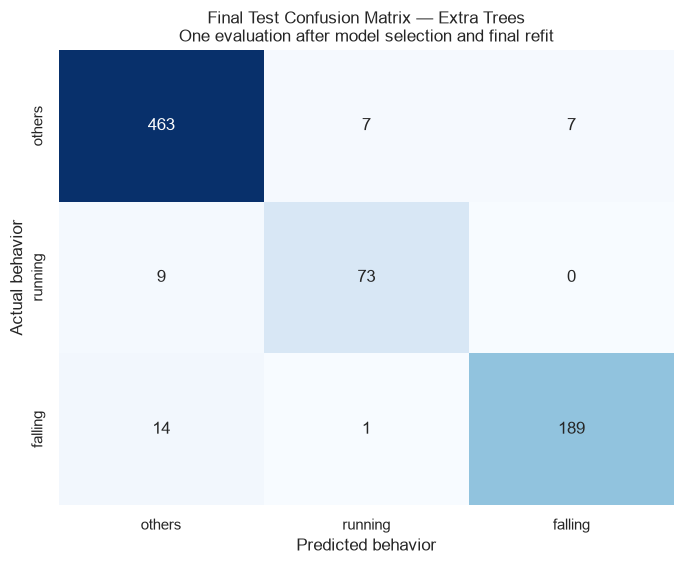

In [11]:
# Evaluate the locked model in one test prediction pass.
# This is the first API call that receives X_test; the returned probabilities are
# mapped through model.classes_ rather than assumed to follow display order.
test_results = evaluate_final_test_set(
    final_model, X_test, y_test, CLASS_MAPPING, PROBABILITY_ORDER
)
# Unpack separate reporting views from the single inference pass to avoid predicting
# the test set again for tables, figures, or CSV export.
test_summary = test_results["summary"]
test_per_class = test_results["per_class"]
test_confusion = test_results["confusion_matrix"]
test_predictions = test_results["predictions"]

# Pair a one-line aggregate summary with a small per-class table; this keeps class
# imbalance visible without presenting a wide classification report.
print(
    f"Accuracy: {test_summary['accuracy']:.4f} | "
    f"Macro F1: {test_summary['macro_f1']:.4f} | "
    f"Weighted F1: {test_summary['weighted_f1']:.4f} | "
    f"Inference: {test_summary['inference_time_seconds']:.4f} s"
)
display(test_per_class.round(4))

# The annotated matrix reveals which behavior pairs drive the aggregate metrics.
final_test_confusion_matrix_figure, ax = plt.subplots(figsize=(7, 5.8))
sns.heatmap(
    test_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=list(CLASS_MAPPING.values()),
    yticklabels=list(CLASS_MAPPING.values()),
    ax=ax,
)
ax.set_title(
    f"Final Test Confusion Matrix — {selected_model_name}\nOne evaluation after model selection and final refit"
)
ax.set(xlabel="Predicted behavior", ylabel="Actual behavior")
final_test_confusion_matrix_figure.tight_layout()
plt.show()

# Compute post-hoc diagnostics for the written observation only. These values must
# not trigger model reselection or any new test-informed tuning.
validation_to_test_drop = (
    float(selection["selected_row"]["mean_validation_macro_f1"])
    - test_summary["macro_f1"]
)
strongest_class = test_per_class.loc[test_per_class["f1"].idxmax(), "class_name"]
weakest_class = test_per_class.loc[test_per_class["f1"].idxmin(), "class_name"]

_Figure: Rows are actual classes and columns are predicted classes._

### Observation

- **Result:** Saved test accuracy is `0.9502` and macro F1 is `0.9341`. Per-class F1 is `0.9616` for others, `0.8957` for running and `0.9450` for falling.
- **Interpretation:** The table and confusion matrix show the recorded model's per-class results.
- **Decision:** Retain the selected configuration and report these saved outputs.


## 13. Save experiment artifacts

**Purpose:** Persist the minimal model, tabular results, and figures needed for deployment and reporting.

**Inputs:** Locked model, selected configuration, final results, five approved figures, and the descriptive experiment identifier.

**Outputs:** One new experiment folder containing exactly `figures/`, `csv/`, and `model/`.

**Guardrails:** The saver uses an explicit allowlist and refuses to overwrite an existing experiment. No Optuna database, raw trial history, intermediate model, or duplicate report is emitted.


In [12]:
# Create the experiment folder late and save only the approved final artifacts.
# Directory creation is delayed until all modeling stages succeed; the helper refuses
# an existing experiment ID instead of overwriting prior evidence.
experiment_paths = create_experiment_paths(ARTIFACT_ROOT, EXPERIMENT_ID)
# Save exactly five descriptive figures and five CSV reports. This explicit allowlist
# prevents trial histories, debug plots, or duplicate reports from accumulating.
saved_artifacts = [
    save_figure(
        dataset_distribution_figure,
        experiment_paths["figures"] / "dataset_class_distribution.png",
    ),
    save_figure(
        validation_model_comparison_figure,
        experiment_paths["figures"] / "validation_model_comparison.png",
    ),
    save_figure(
        validation_seed_stability_figure,
        experiment_paths["figures"] / "validation_seed_stability.png",
    ),
    save_figure(
        selected_model_feature_importance_figure,
        experiment_paths["figures"] / "selected_model_feature_importance.png",
    ),
    save_figure(
        final_test_confusion_matrix_figure,
        experiment_paths["figures"] / "final_test_confusion_matrix.png",
    ),
    save_dataframe(
        model_comparison, experiment_paths["csv"] / "validation_model_comparison.csv"
    ),
    save_dataframe(
        stability_summary,
        experiment_paths["csv"] / "validation_seed_stability_summary.csv",
    ),
    save_dataframe(
        feature_importance,
        experiment_paths["csv"] / "selected_model_feature_importance.csv",
    ),
    save_dataframe(
        test_results["metrics_table"],
        experiment_paths["csv"] / "final_test_classification_metrics.csv",
    ),
    save_dataframe(
        test_predictions, experiment_paths["csv"] / "final_test_predictions.csv"
    ),
]

# Store the complete inference contract beside the model: feature order, class and
# probability mappings, selection evidence, metrics, and library versions.
model_metadata = {
    "experiment_id": EXPERIMENT_ID,
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "model_name": selected_model_name,
    "resolved_hyperparameters": selected_hyperparameters,
    "selected_seed": selected_seed,
    "explicit_iteration_count": selected_iteration_count,
    "class_mapping": CLASS_MAPPING,
    "ordered_feature_names": feature_names,
    "probability_column_order": PROBABILITY_ORDER,
    "selection_rule": "Within 0.005 of best mean validation macro F1, prefer lower seed std, absolute gap, complexity, then inference time.",
    "validation_summary": selection["selected_row"].to_dict(),
    "test_summary": test_summary,
    "library_versions": relevant_library_versions(),
}
# Serialize only the locked final estimator and its metadata; no candidate or
# intermediate development model is persisted.
saved_artifacts.extend(
    save_model_bundle(final_model, model_metadata, experiment_paths["model"])
)
# Print the known saved paths directly instead of scanning the artifact directory.
print(
    f"Saved {len(saved_artifacts)} approved artifacts under {experiment_paths['root']}:\n"
)
print(format_saved_artifacts(saved_artifacts, experiment_paths["root"]))

Saved 12 approved artifacts under C:\Github\smart-factory-safety-monitoring-system\behavioral-detection\artifacts\20260825_tree_ensemble_refactor_v01:

- figures\dataset_class_distribution.png
- figures\validation_model_comparison.png
- figures\validation_seed_stability.png
- figures\selected_model_feature_importance.png
- figures\final_test_confusion_matrix.png
- csv\validation_model_comparison.csv
- csv\validation_seed_stability_summary.csv
- csv\selected_model_feature_importance.csv
- csv\final_test_classification_metrics.csv
- csv\final_test_predictions.csv
- model\selected_behavior_classifier.joblib
- model\selected_behavior_classifier_metadata.json


### Observation

- **Result:** A successful run writes 12 descriptive files: five figures, five CSV files, one classifier, and one model metadata file.
- **Interpretation:** The experiment folder contains only results needed to understand, reproduce, or deploy the selected model.
- **Decision:** Treat the experiment directory as immutable. Use a new versioned ID for every later end-to-end experiment.


## 14. Final conclusion

Experiment `20260825_tree_ensemble_refactor_v01` selected **Extra Trees**, seed `17`, with mean validation macro F1 `0.9208` and seed standard deviation `0.0036`.

After refitting on 4,386 development rows, the saved test output records accuracy `0.9502` and macro F1 `0.9341`. Per-class F1 is `0.9616` for others, `0.8957` for running and `0.9450` for falling.

Source: the experiment's metadata and CSV reports under `artifacts/20260825_tree_ensemble_refactor_v01/`. The [Behavior README](README.md) documents how to prepare another run; [MODELS](../docs/MODELS.md) summarizes the recorded results.

The selection applies to the declared model families, search spaces, budgets and validation protocol. Use a new experiment ID for further work.
